# Project 2: Predicting Used-Car Prices

**Goal:** predict `Selling_Price` from vehicle details and compare Multiple Linear Regression with ensemble/tree-based regressors.

We will use the supplied CarDekho CSV. Run the notebook from top to bottom. The target values remain in the dataset's own units; they are not automatically Ghana cedis.


In [24]:

def predict_car_price(present_price, kms_driven, owner,
                      vehicle_age, fuel_type,
                      seller_type, transmission):

    # Convert vehicle details into model input format
    car = pd.DataFrame([{
        "Present_Price": present_price,
        "Kms_Driven": kms_driven,
        "Owner": owner,
        "Vehicle_Age": vehicle_age,
        "Fuel_Type_Diesel": 1 if fuel_type == "Diesel" else 0,
        "Fuel_Type_Petrol": 1 if fuel_type == "Petrol" else 0,
        "Seller_Type_Individual": 1 if seller_type == "Individual" else 0,
        "Transmission_Manual": 1 if transmission == "Manual" else 0
    }])

    prediction = loaded_gb.predict(car)

    return prediction[0]


# Test the prediction function
price = predict_car_price(
    present_price=5.59,
    kms_driven=27000,
    owner=0,
    vehicle_age=8,
    fuel_type="Petrol",
    seller_type="Individual",
    transmission="Manual"
)

print("Estimated Selling Price:", round(price, 2))


Estimated Selling Price: 4.47


In [23]:

# Sample car details
sample_car = pd.DataFrame([{
    "Present_Price": 5.59,
    "Kms_Driven": 27000,
    "Owner": 0,
    "Vehicle_Age": 8,
    "Fuel_Type_Diesel": 0,
    "Fuel_Type_Petrol": 1,
    "Seller_Type_Individual": 1,
    "Transmission_Manual": 1
}])

# Predict using Gradient Boosting
predicted_price = loaded_gb.predict(sample_car)

print("Predicted Selling Price:", predicted_price[0])


Predicted Selling Price: 4.466923935338669


In [21]:

import joblib

# Save all four trained models
joblib.dump(lr_model, "linear_regression_model.pkl")
joblib.dump(dt_model, "decision_tree_model.pkl")
joblib.dump(rf_model, "random_forest_model.pkl")
joblib.dump(gb_model, "gradient_boosting_model.pkl")

print("All four models have been saved successfully!")


All four models have been saved successfully!


In [22]:

# Load the saved models
loaded_lr = joblib.load("linear_regression_model.pkl")
loaded_dt = joblib.load("decision_tree_model.pkl")
loaded_rf = joblib.load("random_forest_model.pkl")
loaded_gb = joblib.load("gradient_boosting_model.pkl")

print("All four saved models loaded successfully!")


All four saved models loaded successfully!


In [3]:
print("Dataset dimensions:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

Dataset dimensions:
(301, 9)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB

Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Duplicate records:
2


In [5]:
# Create vehicle age
df["Vehicle_Age"] = 2026 - df["Year"]

# Display the first five records
print(df[["Car_Name", "Year", "Vehicle_Age"]].head())

  Car_Name  Year  Vehicle_Age
0     ritz  2014           12
1      sx4  2013           13
2     ciaz  2017            9
3  wagon r  2011           15
4    swift  2014           12


In [6]:
# Select the input features
X = df.drop(columns=[
    "Selling_Price",
    "Car_Name",
    "Year"
])

# Select the target variable
y = df["Selling_Price"]

# Convert categorical variables into numerical variables
X = pd.get_dummies(
    X,
    columns=["Fuel_Type", "Seller_Type", "Transmission"],
    drop_first=True,
    dtype=int
)

# Display the prepared features
print(X.head())

# Display the target variable
print("\nTarget variable:")
print(y.head())

   Present_Price  Kms_Driven  Owner  Vehicle_Age  Fuel_Type_Diesel  \
0           5.59       27000      0           12                 0   
1           9.54       43000      0           13                 1   
2           9.85        6900      0            9                 0   
3           4.15        5200      0           15                 0   
4           6.87       42450      0           12                 1   

   Fuel_Type_Petrol  Seller_Type_Individual  Transmission_Manual  
0                 1                       0                    1  
1                 0                       0                    1  
2                 1                       0                    1  
3                 1                       0                    1  
4                 0                       0                    1  

Target variable:
0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: Selling_Price, dtype: float64


In [7]:
print("Number of input features:", X.shape[1])

print("\nFeature names:")
print(X.columns.tolist())

print("\nTarget shape:")
print(y.shape)

print("\nData types:")
print(X.dtypes)


Number of input features: 8

Feature names:
['Present_Price', 'Kms_Driven', 'Owner', 'Vehicle_Age', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Seller_Type_Individual', 'Transmission_Manual']

Target shape:
(299,)

Data types:
Present_Price             float64
Kms_Driven                  int64
Owner                       int64
Vehicle_Age                 int64
Fuel_Type_Diesel            int64
Fuel_Type_Petrol            int64
Seller_Type_Individual      int64
Transmission_Manual         int64
dtype: object


In [8]:
from sklearn.model_selection import train_test_split

# Divide the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display the sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (239, 8)
Testing features: (60, 8)
Training target: (239,)
Testing target: (60,)


In [4]:
# Remove duplicate records
df = df.drop_duplicates()

# Check the new dataset dimensions
print("Dataset dimensions after cleaning:", df.shape)

# Check duplicates again
print("Remaining duplicates:", df.duplicated().sum())

Dataset dimensions after cleaning: (299, 9)
Remaining duplicates: 0


In [9]:
from sklearn.linear_model import LinearRegression

# Create the Multiple Linear Regression model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

print("Multiple Linear Regression model trained successfully!")

Multiple Linear Regression model trained successfully!


In [10]:
# Predict selling prices for the test data
y_pred_lr = lr_model.predict(X_test)

# Display the first five predictions
print("Predicted prices:")
print(y_pred_lr[:5])

print("\nActual prices:")
print(y_test.head().values)

Predicted prices:
[ 7.50192151  7.79152142  1.36644388  7.00941894 11.16328988]

Actual prices:
[8.99 8.35 0.45 7.45 5.25]


In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_lr)

mse = mean_squared_error(y_test, y_pred_lr)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred_lr)

print("MULTIPLE LINEAR REGRESSION RESULTS")
print("----------------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MULTIPLE LINEAR REGRESSION RESULTS
----------------------------------
MAE: 1.4728924140033002
MSE: 6.370752956823281
RMSE: 2.524035054594781
R2 Score: 0.7528154215832914


In [2]:
import pandas as pd
import numpy as np
import sklearn
import joblib

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)

All libraries imported successfully!
Pandas version: 3.1.1


In [12]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

# Create the models
dt_model = DecisionTreeRegressor(random_state=42)

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

gb_model = GradientBoostingRegressor(random_state=42)

# Train the models
dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
gb_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")
print("Random Forest trained successfully!")
print("Gradient Boosting trained successfully!")

Decision Tree trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!


In [13]:
# Generate predictions using each model

y_pred_lr = lr_model.predict(X_test)

y_pred_dt = dt_model.predict(X_test)

y_pred_rf = rf_model.predict(X_test)

y_pred_gb = gb_model.predict(X_test)

print("All four models have made predictions successfully!")

All four models have made predictions successfully!


In [14]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Store all models and their predictions
models = {
    "Multiple Linear Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb
}

# Evaluate each model
results = []

for name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Create comparison table
results_df = pd.DataFrame(results)

print(results_df.round(4))

                        Model     MAE      MSE    RMSE  R2 Score
0  Multiple Linear Regression  1.4729   6.3708  2.5240    0.7528
1               Decision Tree  1.3333   8.5023  2.9159    0.6701
2               Random Forest  1.4075  11.0389  3.3225    0.5717
3           Gradient Boosting  1.1646   6.8728  2.6216    0.7333


In [1]:
import sys

print(sys.executable)

c:\Users\USER\AppData\Local\Programs\Python\Python313\python.exe


## 1. Import libraries and load the dataset

In [2]:
df = pd.read_csv("car data.csv")

print(df.head())

  Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Seller_Type Transmission  Owner  
0      Dealer       Manual      0  
1      Dealer       Manual      0  
2      Dealer       Manual      0  
3      Dealer       Manual      0  
4      Dealer       Manual      0  


In [6]:
import pandas as pd
import numpy as np

df = pd.read_csv("car data.csv")
print("Shape:", df.shape)
display(df.head())
print(df.info())


ModuleNotFoundError: No module named 'pandas'

In [19]:
import matplotlib.pyplot as plt

print("Matplotlib imported successfully!")

Matplotlib imported successfully!


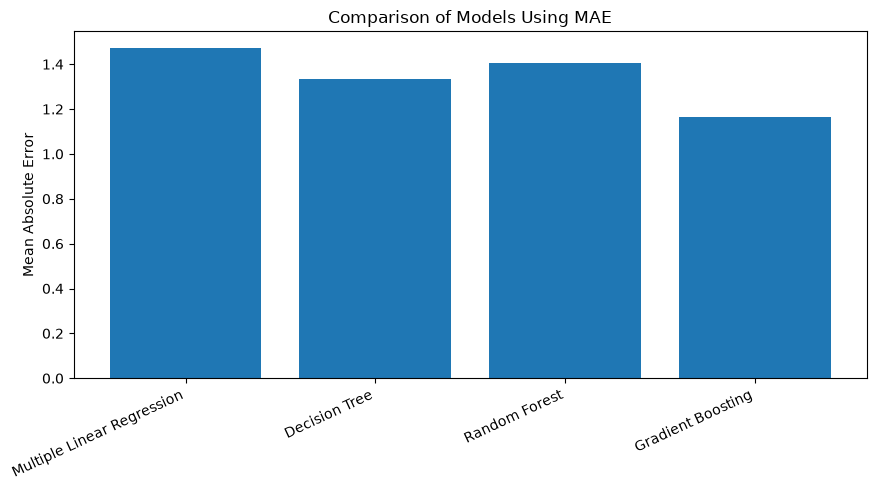

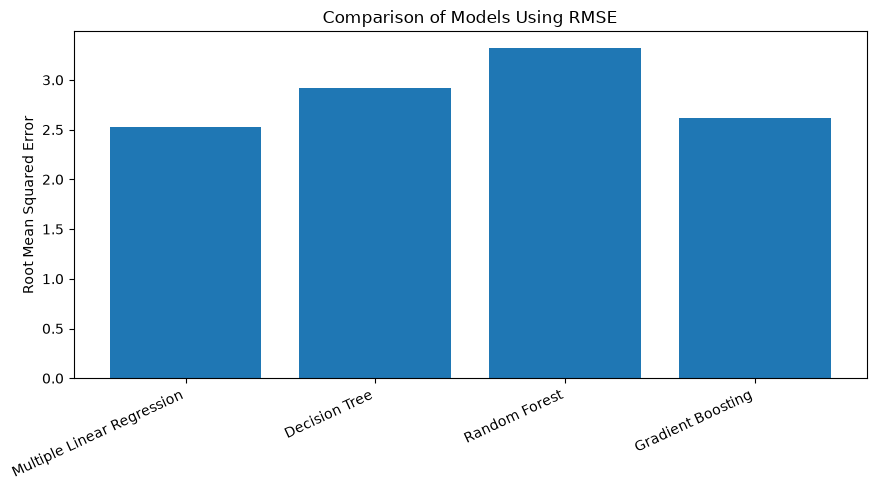

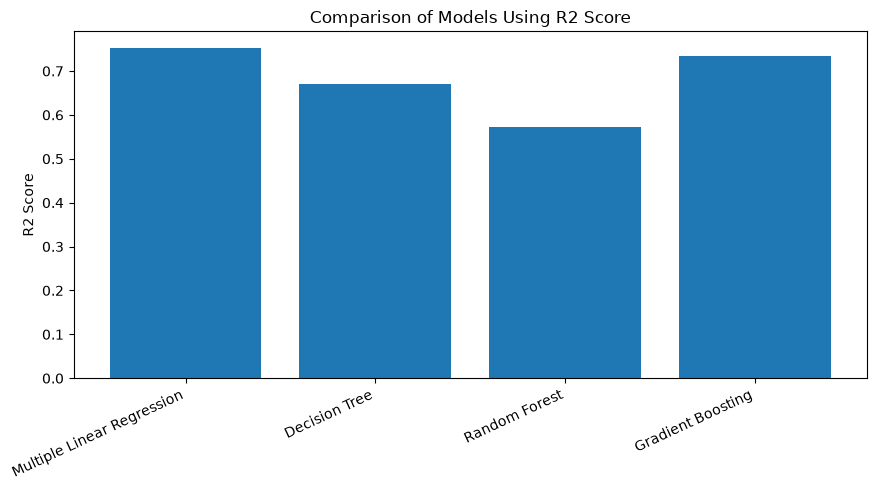

In [20]:

import matplotlib.pyplot as plt

# Extract values from the comparison table
model_names = results_df["Model"]
mae_values = results_df["MAE"]
rmse_values = results_df["RMSE"]
r2_values = results_df["R2 Score"]

# MAE comparison
plt.figure(figsize=(9, 5))
plt.bar(model_names, mae_values)
plt.title("Comparison of Models Using MAE")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# RMSE comparison
plt.figure(figsize=(9, 5))
plt.bar(model_names, rmse_values)
plt.title("Comparison of Models Using RMSE")
plt.ylabel("Root Mean Squared Error")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# R2 comparison
plt.figure(figsize=(9, 5))
plt.bar(model_names, r2_values)
plt.title("Comparison of Models Using R2 Score")
plt.ylabel("R2 Score")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


In [1]:
import pandas as pd
import numpy as np

print("Pandas is working!")
print(pd.__version__)

Pandas is working!
3.1.1


## 2. Inspect and clean the data
We check missing values and remove duplicate rows. We do not invent missing records.

In [ ]:
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Shape after removing duplicates:", df.shape)


## 3. Create a useful feature: vehicle age
A newer vehicle is generally worth more, so we convert manufacturing year into age. Keep this reference year consistent when predicting later.

In [ ]:
REFERENCE_YEAR = 2026
df["Vehicle_Age"] = REFERENCE_YEAR - df["Year"]
display(df[["Year", "Vehicle_Age", "Selling_Price"]].head())


## 4. Separate input features and target
`Selling_Price` is what we want the model to predict. `Year` is replaced by the engineered `Vehicle_Age` feature.

In [ ]:
X = df.drop(columns=["Selling_Price", "Year"])
y = df["Selling_Price"]
categorical = X.select_dtypes(include=["object"]).columns.tolist()
numeric = X.select_dtypes(exclude=["object"]).columns.tolist()
print("Categorical:", categorical)
print("Numeric:", numeric)


## 5. Split into training and testing data
The model learns from 80% and is evaluated on the held-out 20%. `random_state=42` makes the split reproducible.

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)


## 6. Preprocess features
Numbers are scaled; text categories are converted into numeric indicator columns (one-hot encoding). The preprocessing is fitted only on training data through the pipeline.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical)
])


## 7. Train the four models
Multiple Linear Regression is the required baseline. We compare it with Decision Tree, Random Forest, and Gradient Boosting.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Multiple Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(
        random_state=42, max_depth=5, min_samples_leaf=2
    ),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=300, random_state=42, min_samples_leaf=2
    ),
    "Gradient Boosting Regressor": GradientBoostingRegressor(
        random_state=42, n_estimators=200, learning_rate=0.05, max_depth=2
    )
}

results = []
fitted = {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocessing", preprocessor), ("regressor", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mean_squared_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df)


## 8. Understand the evaluation metrics
- **MAE:** average absolute prediction error; lower is better.
- **MSE:** average squared error; lower is better and large errors are penalized more.
- **RMSE:** square root of MSE; lower is better.
- **R²:** proportion of target variation explained by the model; closer to 1 is generally better.

## 9. Save the best model
We choose the model with the lowest test MAE, then refit it on all cleaned data for the final saved artifact. Keep the test metrics above as the honest evaluation.

In [ ]:
import joblib

best_name = results_df.iloc[0]["Model"]
print("Best model by MAE:", best_name)

best_model = Pipeline([
    ("preprocessing", preprocessor),
    ("regressor", models[best_name])
])
best_model.fit(X, y)
joblib.dump(best_model, "best_used_car_price_model.joblib")
print("Model saved.")


## 10. Make a prediction
Enter a vehicle's details. The output is in the same units as `Selling_Price` in the supplied dataset.

In [ ]:
example_car = pd.DataFrame([{
    "Car_Name": "ritz",
    "Present_Price": 5.59,
    "Kms_Driven": 27000,
    "Fuel_Type": "Petrol",
    "Seller_Type": "Dealer",
    "Transmission": "Manual",
    "Owner": 0,
    "Vehicle_Age": REFERENCE_YEAR - 2014
}])

estimated_price = best_model.predict(example_car)[0]
print("Estimated selling price:", round(float(estimated_price), 3))


## 11. Project limitations
- This dataset has only a few hundred rows, so results may change with a different train/test split.
- It represents the market and price units of its source; it is not automatically a Ghana used-car pricing model.
- A prediction is an estimate, not a guaranteed selling price.
- Before deployment, test on newer and locally relevant data and consider cross-validation.
